In [ ]:
# ============================================================
# PREDIKSI PERFORMA PEMBELAJARAN SISWA
# BERBASIS MACHINE LEARNING DAN EXPLAINABLE AI (XAI)
# ============================================================

# ===========================
# IMPORT LIBRARY
# ===========================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    StratifiedKFold,
    cross_val_score
)

from sklearn.preprocessing import (
    LabelEncoder,
    StandardScaler
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

from xgboost import XGBClassifier

import shap

import joblib

# Random Seed
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [ ]:
# ============================================================
# LOAD DATASET
# ============================================================

from google.colab import files

uploaded = files.upload()

# ============================================================
# MEMBACA DATASET
# ============================================================

filename = list(uploaded.keys())[0]

df = pd.read_csv(filename)

print("Dataset berhasil dimuat.\n")

print("Nama File :", filename)
print("Jumlah Baris :", df.shape[0])
print("Jumlah Kolom :", df.shape[1])

display(df.head())

Saving lms_dataset_training.csv to lms_dataset_training (1).csv
Dataset berhasil dimuat.

Nama File : lms_dataset_training (1).csv
Jumlah Baris : 500
Jumlah Kolom : 10


,student_id,jumlah_login,rata_rata_durasi_sesi,jumlah_tugas_dikumpulkan,jumlah_postingan_forum,jumlah_percobaan_kuis,tingkat_keterlambatan_pengumpulan,rata_rata_nilai_kuis,total_waktu_belajar,tingkat_performa
0,S0001,34,27.10,13,3,3,1,92.94,35.54,Sedang
1,S0002,121,43.90,16,28,7,1,54.00,58.45,Sedang
2,S0003,51,27.44,14,20,1,1,49.00,39.24,Sedang
3,S0004,150,34.82,20,14,4,0,92.74,53.11,Tinggi
4,S0005,105,41.69,20,15,6,2,93.25,60.15,Tinggi


In [ ]:
# ============================================================
# INFORMASI DATASET
# ============================================================

print("="*60)
print("INFORMASI DATASET")
print("="*60)

display(df.info())

print("\n")

display(df.describe())

print("\n")

print("Ukuran Dataset :", df.shape)

INFORMASI DATASET
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 10 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   student_id                         500 non-null    object 
 1   jumlah_login                       500 non-null    int64  
 2   rata_rata_durasi_sesi              500 non-null    float64
 3   jumlah_tugas_dikumpulkan           500 non-null    int64  
 4   jumlah_postingan_forum             500 non-null    int64  
 5   jumlah_percobaan_kuis              500 non-null    int64  
 6   tingkat_keterlambatan_pengumpulan  500 non-null    int64  
 7   rata_rata_nilai_kuis               500 non-null    float64
 8   total_waktu_belajar                500 non-null    float64
 9   tingkat_performa                   500 non-null    object 
dtypes: float64(3), int64(5), object(2)
memory usage: 39.2+ KB


None

,jumlah_login,rata_rata_durasi_sesi,jumlah_tugas_dikumpulkan,jumlah_postingan_forum,jumlah_percobaan_kuis,tingkat_keterlambatan_pengumpulan,rata_rata_nilai_kuis,total_waktu_belajar
count,500.000000,500.000000,500.00000,500.000000,500.000000,500.00000,500.000000,500.000000
mean,91.454000,29.940920,14.41200,10.936000,5.632000,2.55800,75.013940,42.999200
std,48.674864,13.060849,4.97914,7.159219,3.022391,2.65947,18.182047,20.620776
min,1.000000,2.000000,1.00000,0.000000,1.000000,0.00000,20.230000,2.000000
25%,46.000000,18.850000,12.00000,5.000000,3.000000,0.00000,61.000000,24.140000
50%,103.000000,30.895000,16.00000,11.000000,6.000000,2.00000,78.960000,48.015000
75%,134.000000,39.882500,18.00000,17.000000,8.000000,4.00000,90.230000,59.600000
max,179.000000,60.000000,20.00000,28.000000,12.000000,10.00000,100.000000,80.000000




Ukuran Dataset : (500, 10)


In [ ]:
# ============================================================
# TIPE DATA
# ============================================================

df.dtypes

,0
student_id,object
jumlah_login,int64
rata_rata_durasi_sesi,float64
jumlah_tugas_dikumpulkan,int64
jumlah_postingan_forum,int64
jumlah_percobaan_kuis,int64
tingkat_keterlambatan_pengumpulan,int64
rata_rata_nilai_kuis,float64
total_waktu_belajar,float64
tingkat_performa,object


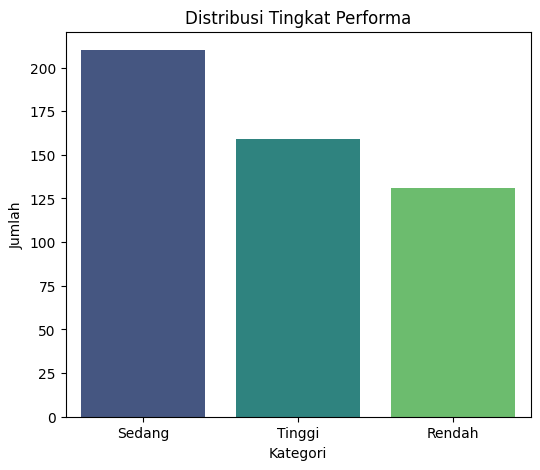

In [ ]:
# ============================================================
# DISTRIBUSI TARGET
# ============================================================

plt.figure(figsize=(6,5))

sns.countplot(
    data=df,
    x="tingkat_performa",
    palette="viridis"
)

plt.title("Distribusi Tingkat Performa")

plt.xlabel("Kategori")

plt.ylabel("Jumlah")

plt.show()

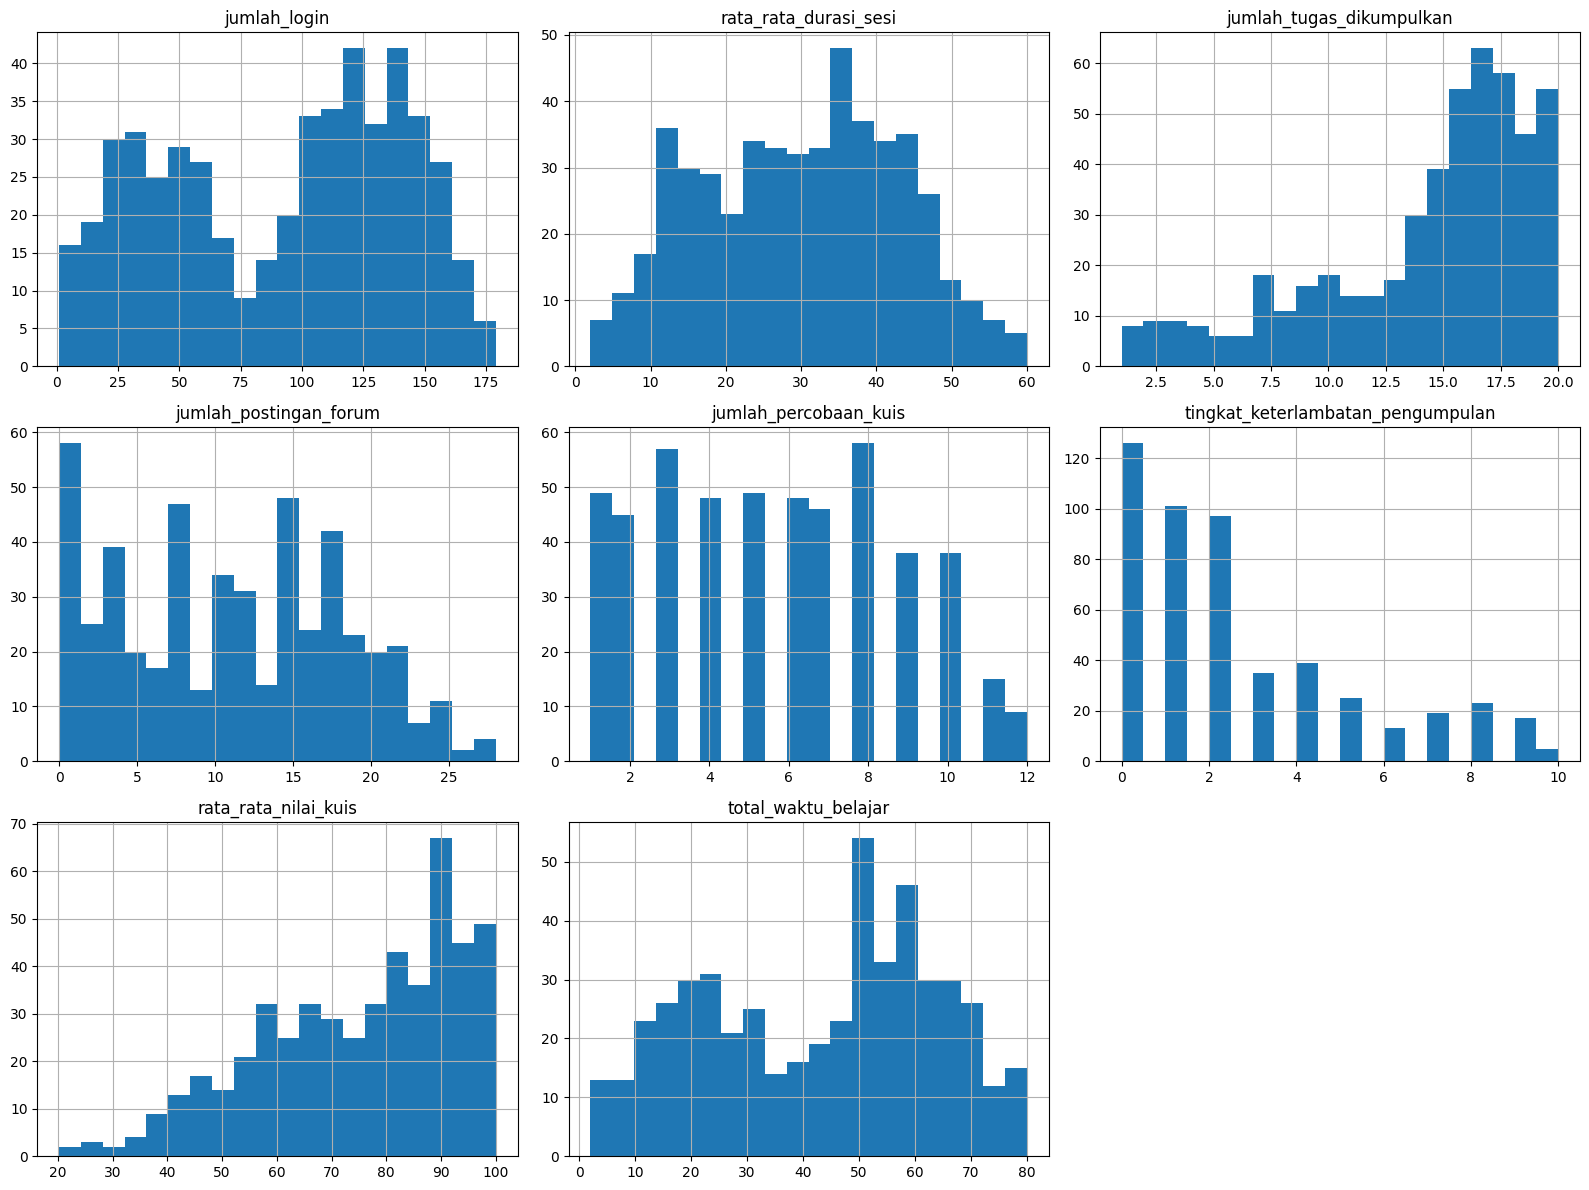

In [ ]:
# ============================================================
# HISTOGRAM FITUR
# ============================================================

numeric_columns = df.select_dtypes(include=np.number).columns

df[numeric_columns].hist(
    figsize=(16,12),
    bins=20
)

plt.tight_layout()

plt.show()

In [ ]:
# ============================================================
# MISSING VALUE
# ============================================================

missing = df.isnull().sum()

missing = pd.DataFrame({

    "Kolom":missing.index,

    "Missing":missing.values

})

display(missing)

,Kolom,Missing
0,student_id,0
1,jumlah_login,0
2,rata_rata_durasi_sesi,0
3,jumlah_tugas_dikumpulkan,0
4,jumlah_postingan_forum,0
5,jumlah_percobaan_kuis,0
6,tingkat_keterlambatan_pengumpulan,0
7,rata_rata_nilai_kuis,0
8,total_waktu_belajar,0
9,tingkat_performa,0


In [ ]:
# ============================================================
# DUPLICATE DATA
# ============================================================

duplicate = df.duplicated().sum()

print("Jumlah Duplicate :", duplicate)

if duplicate>0:

    df = df.drop_duplicates()

    print("Duplicate berhasil dihapus.")

Jumlah Duplicate : 0


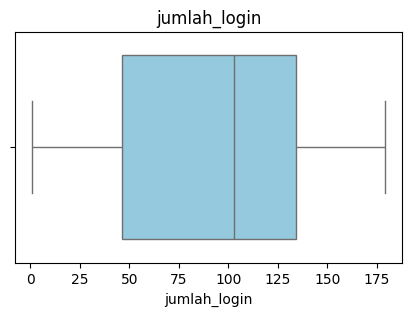

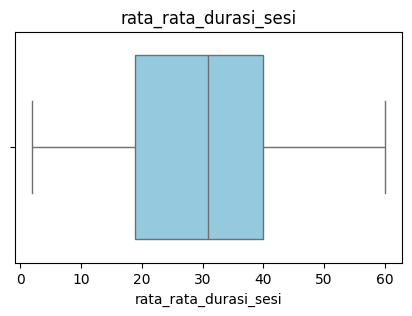

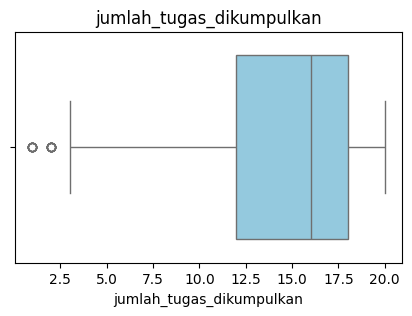

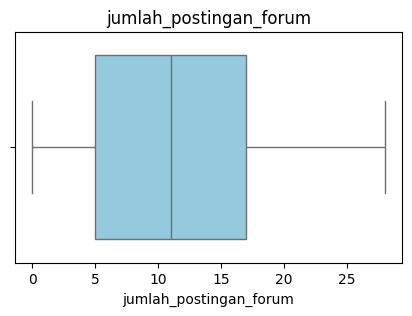

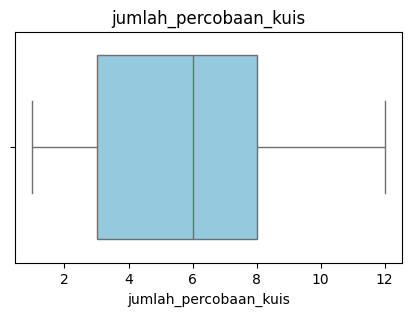

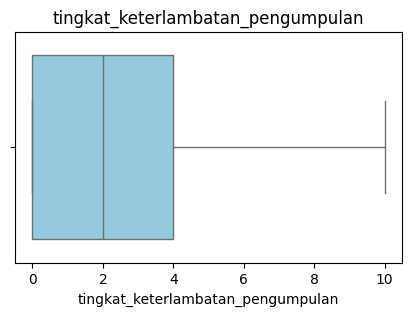

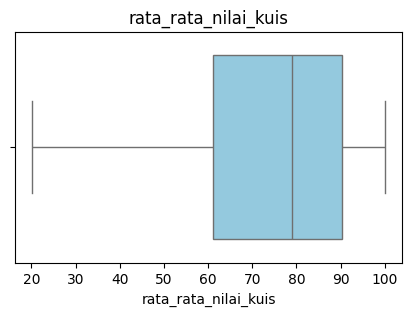

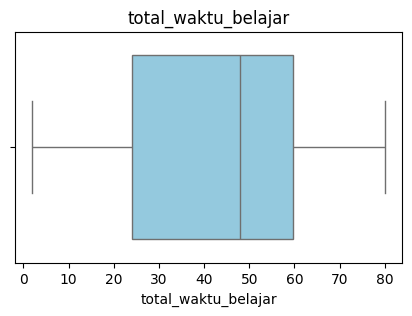

In [ ]:
# ============================================================
# BOXPLOT SELURUH FITUR
# ============================================================

numeric_columns = df.select_dtypes(include=np.number).columns

for column in numeric_columns:

    plt.figure(figsize=(5,3))

    sns.boxplot(
        x=df[column],
        color="skyblue"
    )

    plt.title(column)

    plt.show()

In [ ]:
# ============================================================
# MENGHITUNG OUTLIER DENGAN IQR
# ============================================================

print("="*60)
print("JUMLAH OUTLIER")
print("="*60)

for column in numeric_columns:

    Q1 = df[column].quantile(0.25)

    Q3 = df[column].quantile(0.75)

    IQR = Q3-Q1

    lower = Q1-1.5*IQR

    upper = Q3+1.5*IQR

    total=((df[column]<lower)|(df[column]>upper)).sum()

    print(f"{column:<40} : {total}")

JUMLAH OUTLIER
jumlah_login                             : 0
rata_rata_durasi_sesi                    : 0
jumlah_tugas_dikumpulkan                 : 17
jumlah_postingan_forum                   : 0
jumlah_percobaan_kuis                    : 0
tingkat_keterlambatan_pengumpulan        : 0
rata_rata_nilai_kuis                     : 0
total_waktu_belajar                      : 0


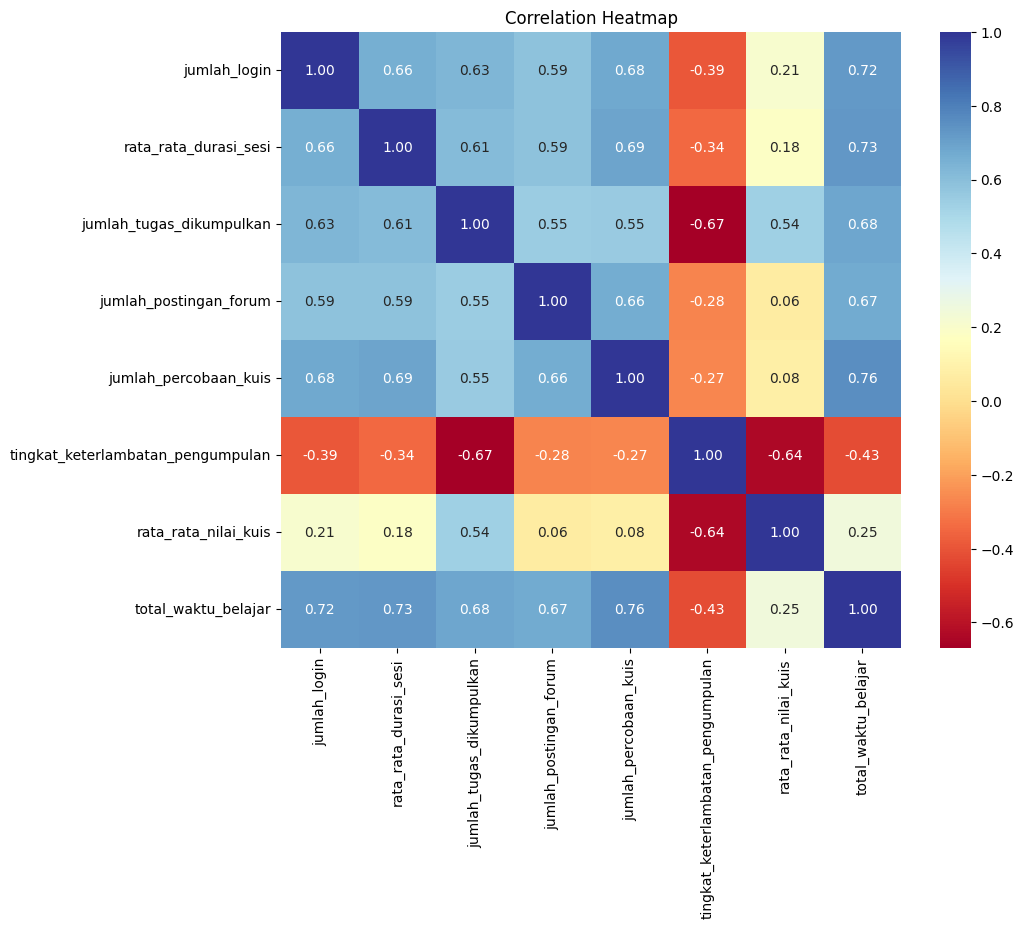

In [ ]:
# ============================================================
# KORELASI
# ============================================================

numeric_df = df.select_dtypes(include=np.number)

corr = numeric_df.corr()

plt.figure(figsize=(10,8))

sns.heatmap(

    corr,

    annot=True,

    cmap="RdYlBu",

    fmt=".2f"

)

plt.title("Correlation Heatmap")

plt.show()

In [ ]:
# ============================================================
# FEATURE DAN TARGET
# ============================================================

X = df.drop(

    columns=[

        "student_id",

        "tingkat_performa"

    ]

)

y = df["tingkat_performa"]

print("Jumlah Feature :", X.shape[1])

print("Nama Feature :")

display(X.columns)

print("\n")

print("Target : tingkat_performa")

Jumlah Feature : 8
Nama Feature :


Index(['jumlah_login', 'rata_rata_durasi_sesi', 'jumlah_tugas_dikumpulkan',
       'jumlah_postingan_forum', 'jumlah_percobaan_kuis',
       'tingkat_keterlambatan_pengumpulan', 'rata_rata_nilai_kuis',
       'total_waktu_belajar'],
      dtype='object')



Target : tingkat_performa


In [ ]:
# ============================================================
# LABEL ENCODING TARGET
# ============================================================

label_encoder = LabelEncoder()

y = label_encoder.fit_transform(y)

print("Mapping Label")

for i,label in enumerate(label_encoder.classes_):

    print(label,"->",i)

Mapping Label
Rendah -> 0
Sedang -> 1
Tinggi -> 2


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("="*60)

print("DATA TRAIN :",X_train.shape)

print("DATA TEST :",X_test.shape)

print("="*60)

DATA TRAIN : (400, 8)
DATA TEST : (100, 8)


In [ ]:
# ============================================================
# FEATURE SCALING
# ============================================================

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Scaling selesai.")

print("\nUkuran X_train_scaled :",X_train_scaled.shape)

print("Ukuran X_test_scaled :",X_test_scaled.shape)

Scaling selesai.

Ukuran X_train_scaled : (400, 8)
Ukuran X_test_scaled : (100, 8)


In [ ]:
# ============================================================
# LOGISTIC REGRESSION
# ============================================================

print("="*60)
print("GRID SEARCH - LOGISTIC REGRESSION")
print("="*60)

param_lr = {
    'C': [0.01, 0.1, 1, 10, 100],
    'solver': ['lbfgs'],
    'max_iter': [1000]
}

grid_lr = GridSearchCV(
    estimator=LogisticRegression(random_state=RANDOM_STATE),
    param_grid=param_lr,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid_lr.fit(X_train_scaled, y_train)

best_lr = grid_lr.best_estimator_

print("Best Parameter :", grid_lr.best_params_)
print("Best CV Score  :", round(grid_lr.best_score_,4))

GRID SEARCH - LOGISTIC REGRESSION
Best Parameter : {'C': 0.1, 'max_iter': 1000, 'solver': 'lbfgs'}
Best CV Score  : 0.7875


In [ ]:
# ============================================================
# RANDOM FOREST
# ============================================================

print("="*60)
print("GRID SEARCH - RANDOM FOREST")
print("="*60)

param_rf = {

    'n_estimators':[100,200,300],

    'max_depth':[None,5,10,20],

    'min_samples_split':[2,5,10],

    'min_samples_leaf':[1,2,4]

}

grid_rf = GridSearchCV(

    estimator=RandomForestClassifier(
        random_state=RANDOM_STATE
    ),

    param_grid=param_rf,

    cv=5,

    scoring='accuracy',

    n_jobs=-1

)

grid_rf.fit(X_train,y_train)

best_rf = grid_rf.best_estimator_

print("Best Parameter :",grid_rf.best_params_)

print("Best CV Score :",round(grid_rf.best_score_,4))

GRID SEARCH - RANDOM FOREST
Best Parameter : {'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 100}
Best CV Score : 0.7825


In [ ]:
# ============================================================
# SUPPORT VECTOR MACHINE
# ============================================================

print("="*60)
print("GRID SEARCH - SVM")
print("="*60)

param_svm = {

    'C':[0.1,1,10],

    'kernel':['linear','rbf'],

    'gamma':['scale','auto']

}

grid_svm = GridSearchCV(

    estimator=SVC(
        probability=True,
        random_state=RANDOM_STATE
    ),

    param_grid=param_svm,

    cv=5,

    scoring='accuracy',

    n_jobs=-1

)

grid_svm.fit(
    X_train_scaled,
    y_train
)

best_svm = grid_svm.best_estimator_

print("Best Parameter :",grid_svm.best_params_)

print("Best CV Score :",round(grid_svm.best_score_,4))

GRID SEARCH - SVM
Best Parameter : {'C': 10, 'gamma': 'scale', 'kernel': 'rbf'}
Best CV Score : 0.8125


In [ ]:
# ============================================================
# XGBOOST
# ============================================================

print("="*60)
print("GRID SEARCH - XGBOOST")
print("="*60)

param_xgb = {

    'n_estimators':[100,200],

    'max_depth':[3,5,7],

    'learning_rate':[0.01,0.1],

    'subsample':[0.8,1.0]

}

grid_xgb = GridSearchCV(

    estimator=XGBClassifier(

        random_state=RANDOM_STATE,

        eval_metric='mlogloss'

    ),

    param_grid=param_xgb,

    cv=5,

    scoring='accuracy',

    n_jobs=-1

)

grid_xgb.fit(
    X_train,
    y_train
)

best_xgb = grid_xgb.best_estimator_

print("Best Parameter :",grid_xgb.best_params_)

print("Best CV Score :",round(grid_xgb.best_score_,4))

GRID SEARCH - XGBOOST
Best Parameter : {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 100, 'subsample': 0.8}
Best CV Score : 0.7775


In [ ]:
# ============================================================
# FUNGSI EVALUASI MODEL
# ============================================================

def evaluate_model(model, X_test, y_test):

    prediction = model.predict(X_test)

    accuracy = accuracy_score(y_test,prediction)

    precision = precision_score(
        y_test,
        prediction,
        average="weighted"
    )

    recall = recall_score(
        y_test,
        prediction,
        average="weighted"
    )

    f1 = f1_score(
        y_test,
        prediction,
        average="weighted"
    )

    return accuracy,precision,recall,f1

In [ ]:
# ============================================================
# EVALUASI MODEL
# ============================================================

results = []

# Logistic Regression
acc,pre,rec,f1 = evaluate_model(
    best_lr,
    X_test_scaled,
    y_test
)

results.append([
    "Logistic Regression",
    acc,
    pre,
    rec,
    f1
])

# Random Forest
acc,pre,rec,f1 = evaluate_model(
    best_rf,
    X_test,
    y_test
)

results.append([
    "Random Forest",
    acc,
    pre,
    rec,
    f1
])

# SVM
acc,pre,rec,f1 = evaluate_model(
    best_svm,
    X_test_scaled,
    y_test
)

results.append([
    "Support Vector Machine",
    acc,
    pre,
    rec,
    f1
])

# XGBoost
acc,pre,rec,f1 = evaluate_model(
    best_xgb,
    X_test,
    y_test
)

results.append([
    "XGBoost",
    acc,
    pre,
    rec,
    f1
])

In [ ]:
# ============================================================
# PERBANDINGAN MODEL
# ============================================================

comparison = pd.DataFrame(

    results,

    columns=[

        "Model",

        "Accuracy",

        "Precision",

        "Recall",

        "F1 Score"

    ]

)

comparison = comparison.sort_values(

    by="Accuracy",

    ascending=False

)

comparison.reset_index(

    drop=True,

    inplace=True

)

display(comparison)

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.81,0.818331,0.81,0.810951
1,Random Forest,0.81,0.821318,0.81,0.812624
2,XGBoost,0.79,0.799256,0.79,0.791670
3,Support Vector Machine,0.77,0.771411,0.77,0.770352


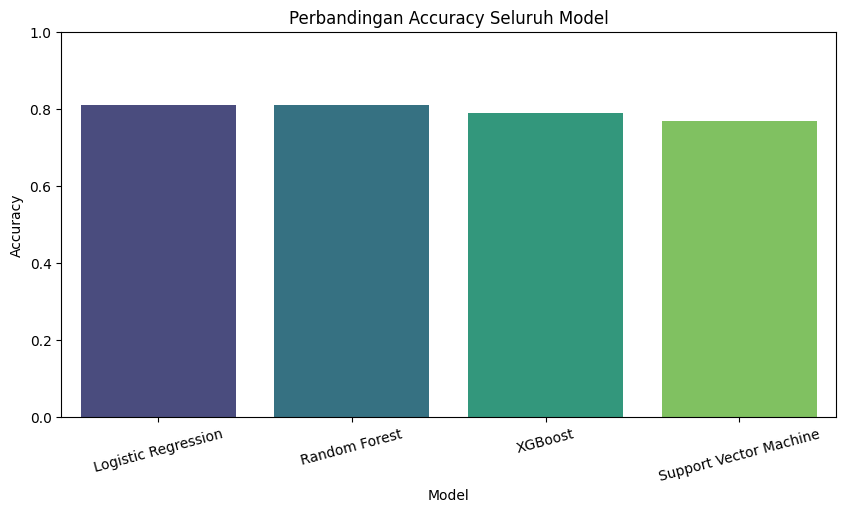

In [ ]:
# ============================================================
# VISUALISASI AKURASI MODEL
# ============================================================

plt.figure(figsize=(10,5))

sns.barplot(

    data=comparison,

    x="Model",

    y="Accuracy",

    palette="viridis"

)

plt.ylim(0,1)

plt.title("Perbandingan Accuracy Seluruh Model")

plt.xticks(rotation=15)

plt.show()

In [ ]:
# ============================================================
# MODEL TERBAIK
# ============================================================

best_model_name = comparison.iloc[0]["Model"]

print("="*60)
print("MODEL TERBAIK")
print("="*60)

print(best_model_name)

if best_model_name=="Logistic Regression":

    best_model = best_lr
    best_X_test = X_test_scaled
    best_X_train = X_train_scaled

elif best_model_name=="Random Forest":

    best_model = best_rf
    best_X_test = X_test
    best_X_train = X_train

elif best_model_name=="Support Vector Machine":

    best_model = best_svm
    best_X_test = X_test_scaled
    best_X_train = X_train_scaled

else:

    best_model = best_xgb
    best_X_test = X_test
    best_X_train = X_train

MODEL TERBAIK
Logistic Regression


In [ ]:
# ============================================================
# CROSS VALIDATION
# ============================================================

print("="*60)
print("CROSS VALIDATION")
print("="*60)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

cv_scores = cross_val_score(
    best_model,
    best_X_train,
    y_train,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

print("Cross Validation Accuracy")

for i, score in enumerate(cv_scores):
    print(f"Fold {i+1} : {score:.4f}")

print("\n")

print(f"Mean Accuracy : {cv_scores.mean():.4f}")
print(f"Std Accuracy  : {cv_scores.std():.4f}")

CROSS VALIDATION
Cross Validation Accuracy
Fold 1 : 0.8125
Fold 2 : 0.7625
Fold 3 : 0.7625
Fold 4 : 0.8250
Fold 5 : 0.7250


Mean Accuracy : 0.7775
Std Accuracy  : 0.0366


In [ ]:
# ============================================================
# PREDIKSI DATA UJI
# ============================================================

y_pred = best_model.predict(best_X_test)

y_prob = best_model.predict_proba(best_X_test)

In [ ]:
# ============================================================
# CLASSIFICATION REPORT
# ============================================================

print("="*60)
print("CLASSIFICATION REPORT")
print("="*60)

print(

    classification_report(

        y_test,

        y_pred,

        target_names=label_encoder.classes_

    )

)

CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Rendah       0.96      0.85      0.90        26
      Sedang       0.79      0.74      0.77        42
      Tinggi       0.74      0.88      0.80        32

    accuracy                           0.81       100
   macro avg       0.83      0.82      0.82       100
weighted avg       0.82      0.81      0.81       100



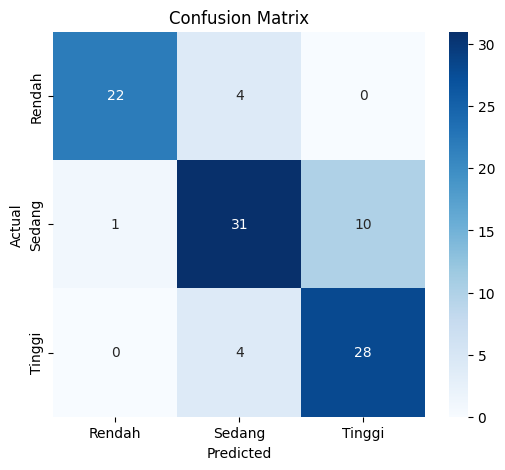

In [ ]:
# ============================================================
# CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_test,
    y_pred
)

plt.figure(figsize=(6,5))

sns.heatmap(

    cm,

    annot=True,

    fmt="d",

    cmap="Blues",

    xticklabels=label_encoder.classes_,

    yticklabels=label_encoder.classes_

)

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.title("Confusion Matrix")

plt.show()

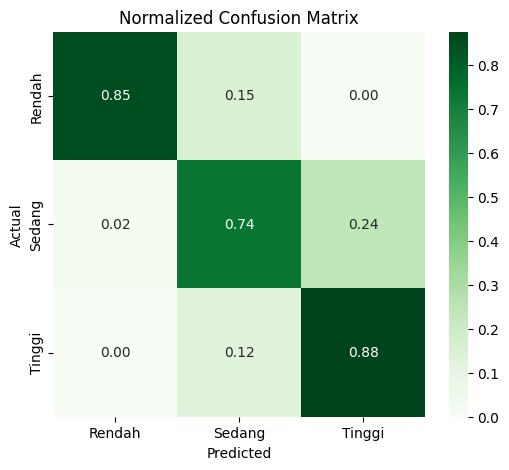

In [ ]:
# ============================================================
# NORMALIZED CONFUSION MATRIX
# ============================================================

cm_normalized = confusion_matrix(
    y_test,
    y_pred,
    normalize="true"
)

plt.figure(figsize=(6,5))

sns.heatmap(

    cm_normalized,

    annot=True,

    fmt=".2f",

    cmap="Greens",

    xticklabels=label_encoder.classes_,

    yticklabels=label_encoder.classes_

)

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.title("Normalized Confusion Matrix")

plt.show()

In [ ]:
from sklearn.preprocessing import label_binarize

from sklearn.metrics import roc_curve, auc

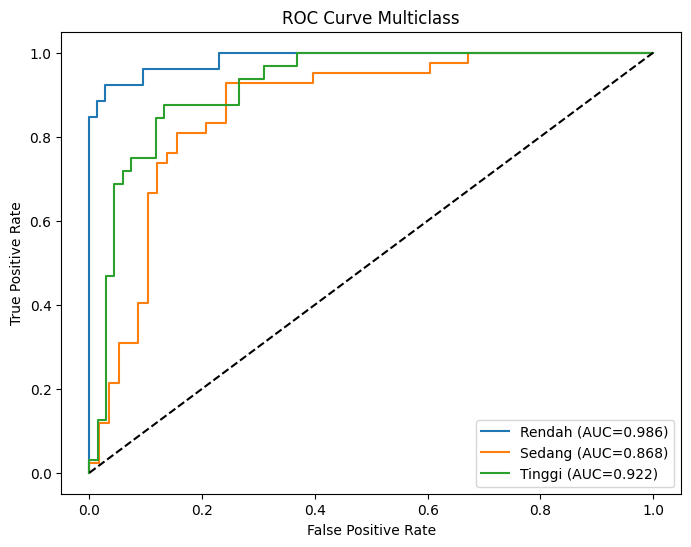

In [ ]:
# ============================================================
# ROC CURVE MULTICLASS
# ============================================================

classes = np.unique(y)

y_test_bin = label_binarize(
    y_test,
    classes=classes
)

plt.figure(figsize=(8,6))

for i in range(len(classes)):

    fpr, tpr, _ = roc_curve(

        y_test_bin[:,i],

        y_prob[:,i]

    )

    roc_auc = auc(fpr,tpr)

    plt.plot(

        fpr,

        tpr,

        label=f"{label_encoder.classes_[i]} (AUC={roc_auc:.3f})"

    )

plt.plot(

    [0,1],

    [0,1],

    linestyle="--",

    color="black"

)

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.title("ROC Curve Multiclass")

plt.legend()

plt.show()

In [ ]:
# ============================================================
# ROC AUC SCORE
# ============================================================

roc_auc = roc_auc_score(

    y_test,

    y_prob,

    multi_class="ovr",

    average="weighted"

)

print("="*60)

print("ROC AUC :",round(roc_auc,4))

print("="*60)

ROC AUC : 0.9158


In [ ]:
# ============================================================
# HASIL AKHIR MODEL TERBAIK
# ============================================================

summary = pd.DataFrame({

    "Metric":[

        "Accuracy",

        "Precision",

        "Recall",

        "F1 Score",

        "ROC AUC",

        "CV Mean",

        "CV Std"

    ],

    "Value":[

        accuracy_score(y_test,y_pred),

        precision_score(
            y_test,
            y_pred,
            average="weighted"
        ),

        recall_score(
            y_test,
            y_pred,
            average="weighted"
        ),

        f1_score(
            y_test,
            y_pred,
            average="weighted"
        ),

        roc_auc,

        cv_scores.mean(),

        cv_scores.std()

    ]

})

display(summary)

,Metric,Value
0,Accuracy,0.810000
1,Precision,0.818331
2,Recall,0.810000
3,F1 Score,0.810951
4,ROC AUC,0.915834
5,CV Mean,0.777500
6,CV Std,0.036572


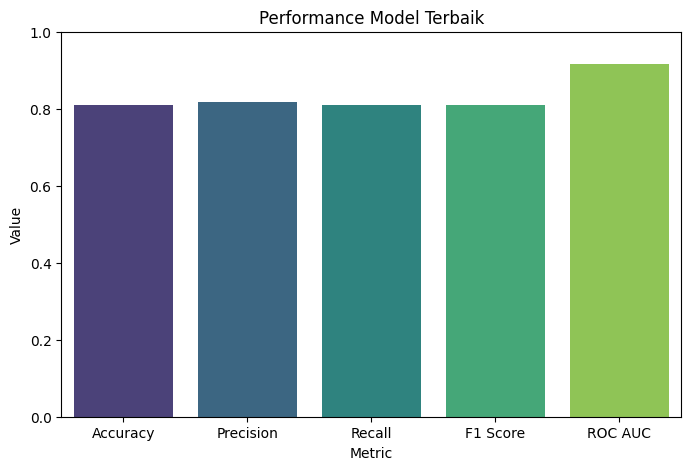

In [ ]:
# ============================================================
# VISUALISASI METRIC
# ============================================================

metric_plot = summary.iloc[:5]

plt.figure(figsize=(8,5))

sns.barplot(

    data=metric_plot,

    x="Metric",

    y="Value",

    palette="viridis"

)

plt.ylim(0,1)

plt.title("Performance Model Terbaik")

plt.show()

In [ ]:
# ============================================================
# MEMILIH SHAP EXPLAINER
# ============================================================

print("="*60)
print("MEMBUAT SHAP EXPLAINER")
print("="*60)

model_name = type(best_model).__name__

print("Model :", model_name)

# -------------------------------
# Tree Based Model
# -------------------------------

if model_name in ["RandomForestClassifier", "XGBClassifier"]:

    explainer = shap.TreeExplainer(best_model)

    shap_values = explainer.shap_values(best_X_test)

    X_shap = pd.DataFrame(
        best_X_test,
        columns=X.columns
    )

# -------------------------------
# Logistic Regression
# -------------------------------

elif model_name == "LogisticRegression":

    explainer = shap.LinearExplainer(
        best_model,
        best_X_train
    )

    shap_values = explainer.shap_values(best_X_test)

    X_shap = pd.DataFrame(
        best_X_test,
        columns=X.columns
    )

# -------------------------------
# SVM
# -------------------------------

else:

    background = shap.sample(
        best_X_train,
        100,
        random_state=RANDOM_STATE
    )

    explainer = shap.KernelExplainer(
        best_model.predict_proba,
        background
    )

    sample_test = best_X_test[:100]

    shap_values = explainer.shap_values(
        sample_test
    )

    X_shap = pd.DataFrame(
        sample_test,
        columns=X.columns
    )

print("SHAP berhasil dibuat.")

MEMBUAT SHAP EXPLAINER
Model : LogisticRegression
SHAP berhasil dibuat.


FEATURE IMPORTANCE


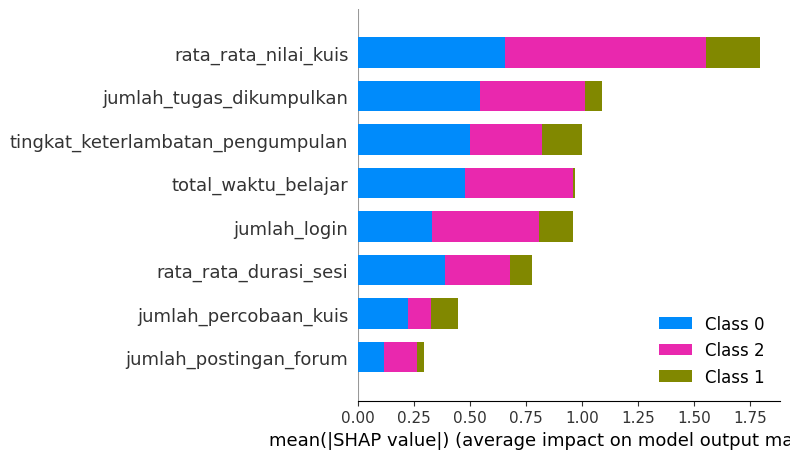

In [ ]:
# ============================================================
# FEATURE IMPORTANCE
# ============================================================

print("="*60)
print("FEATURE IMPORTANCE")
print("="*60)

if isinstance(shap_values, list):

    shap.summary_plot(
        shap_values,
        X_shap,
        plot_type="bar"
    )

else:

    shap.summary_plot(
        shap_values,
        X_shap,
        plot_type="bar"
    )

In [ ]:
# ============================================================
# TABEL FEATURE IMPORTANCE
# ============================================================

if isinstance(shap_values, list):

    # If shap_values is a list of (n_samples, n_features) arrays (common for TreeExplainer/KernelExplainer multi-class)
    # Stack them into a 3D array: (n_samples, n_features, n_classes)
    stacked_shap_values = np.stack(shap_values, axis=-1)
    importance = np.mean(
        np.abs(stacked_shap_values),
        axis=(0, 2) # Mean over samples (axis 0) and classes (axis 2)
    )

else:
    # If shap_values is a single ndarray (can be 2D for single output or 3D for multi-output like LogisticRegression here)
    if shap_values.ndim == 3:
        # For multi-output models where shap_values is already a 3D array (n_samples, n_features, n_classes)
        importance = np.mean(
            np.abs(shap_values),
            axis=(0, 2) # Mean over samples (axis 0) and classes (axis 2)
        )
    elif shap_values.ndim == 2:
        # For single-output models where shap_values is a 2D array (n_samples, n_features)
        importance = np.mean(
            np.abs(shap_values),
            axis=0 # Mean over samples (axis 0)
        )
    else:
        # Handle unexpected dimensions
        raise ValueError("Unsupported shap_values dimensions for importance calculation.")

importance_df = pd.DataFrame({

    "Feature":X.columns,

    "Mean SHAP":importance

})

importance_df = importance_df.sort_values(

    by="Mean SHAP",

    ascending=False

)

display(importance_df)

,Feature,Mean SHAP
6,rata_rata_nilai_kuis,0.598051
2,jumlah_tugas_dikumpulkan,0.363600
5,tingkat_keterlambatan_pengumpulan,0.333819
7,total_waktu_belajar,0.323060
0,jumlah_login,0.319308
1,rata_rata_durasi_sesi,0.258465
4,jumlah_percobaan_kuis,0.148851
3,jumlah_postingan_forum,0.098019


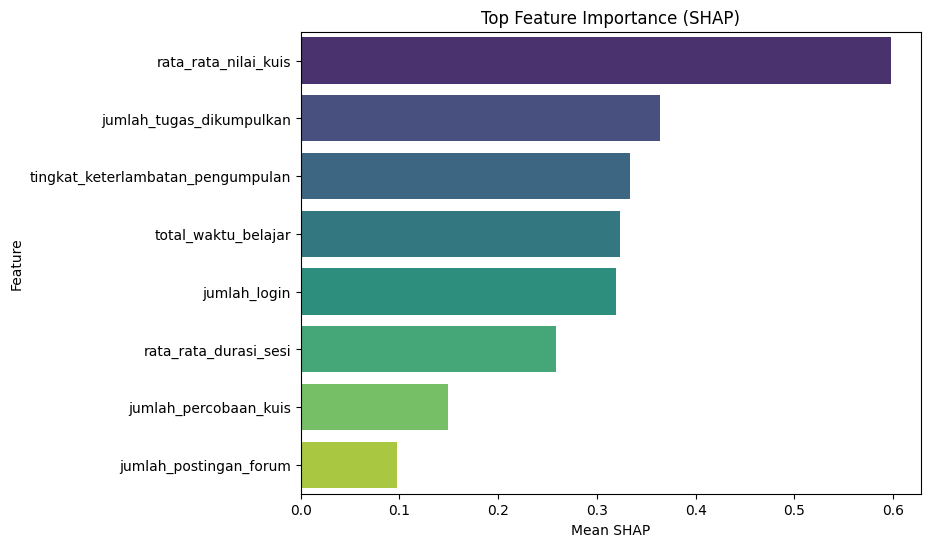

In [ ]:
# ============================================================
# TOP 10 FEATURE
# ============================================================

plt.figure(figsize=(8,6))

sns.barplot(

    data=importance_df.head(10),

    x="Mean SHAP",

    y="Feature",

    palette="viridis"

)

plt.title("Top Feature Importance (SHAP)")

plt.show()

Top Feature : rata_rata_nilai_kuis


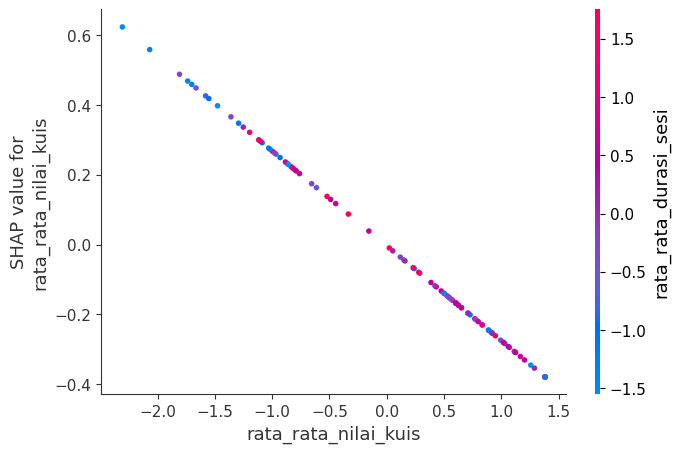

In [ ]:
# ============================================================
# DEPENDENCE PLOT
# ============================================================

top_feature = importance_df.iloc[0]["Feature"]

print("Top Feature :", top_feature)

# If shap_values is a list (e.g., from TreeExplainer multi-output) or a 3D numpy array (e.g., from LinearExplainer multi-output)
if isinstance(shap_values, list):
    # For TreeExplainer/KernelExplainer with multi-class output, shap_values is a list of arrays.
    # We choose the SHAP values for class 1 (index 1) to be consistent with the previous plots.
    shap.dependence_plot(
        top_feature,
        shap_values[1],
        X_shap
    )
elif isinstance(shap_values, np.ndarray) and shap_values.ndim == 3:
    # For LinearExplainer with multi-class output, shap_values is a 3D array (n_samples, n_features, n_classes).
    # We need to select the SHAP values for a specific class, e.g., class 1.
    shap.dependence_plot(
        top_feature,
        shap_values[:, :, 1], # Select SHAP values for class 1 across all samples and features
        X_shap
    )
else:
    # For single-output models or other cases where shap_values is already 2D.
    shap.dependence_plot(
        top_feature,
        shap_values,
        X_shap
    )

Menampilkan penjelasan untuk siswa ke- 0


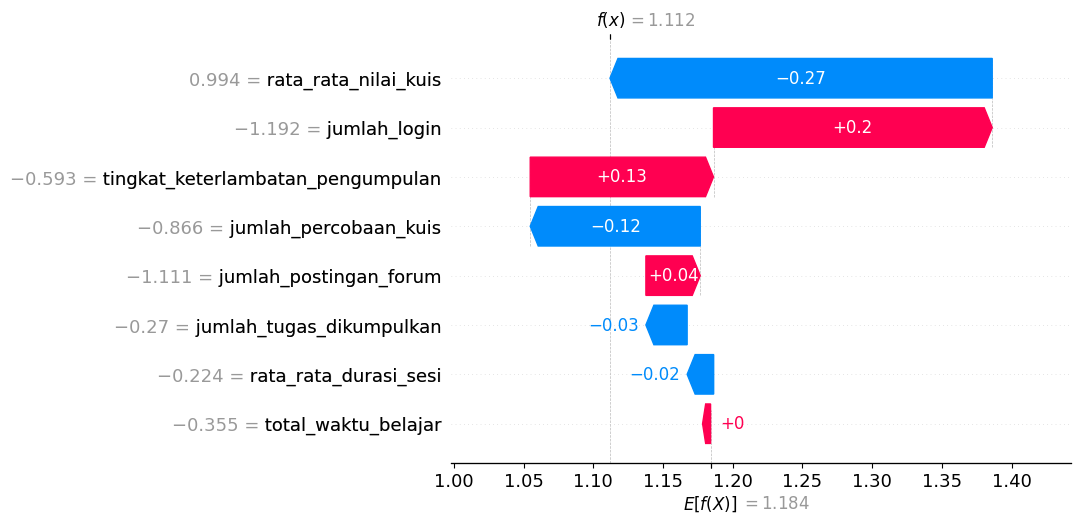

In [ ]:
# ============================================================
# WATERFALL PLOT
# ============================================================

student_index = 0

print("Menampilkan penjelasan untuk siswa ke-", student_index)

if model_name in ["RandomForestClassifier","XGBClassifier"]:

    explanation = shap.Explanation(

        values=shap_values[1][student_index],

        base_values=explainer.expected_value[1],

        data=X_shap.iloc[student_index],

        feature_names=X.columns

    )

elif model_name=="LogisticRegression":

    # For multi-class LogisticRegression, shap_values is (n_samples, n_features, n_classes)
    # We need to select a specific class to explain. Let's use class 1 (index 1) for 'Sedang'.
    class_to_explain = 1
    explanation = shap.Explanation(

        values=shap_values[student_index, :, class_to_explain],

        base_values=explainer.expected_value[class_to_explain],

        data=X_shap.iloc[student_index],

        feature_names=X.columns

    )

else:

    explanation = shap.Explanation(

        values=shap_values[1][student_index],

        base_values=explainer.expected_value[1],

        data=X_shap.iloc[student_index],

        feature_names=X.columns

    )

shap.plots.waterfall(explanation)

In [ ]:
# ============================================================
# SIMPAN MODEL
# ============================================================

import joblib

print("="*60)
print("MENYIMPAN MODEL")
print("="*60)

joblib.dump(best_model, "best_model.pkl")

print("✓ best_model.pkl berhasil disimpan")

MENYIMPAN MODEL
✓ best_model.pkl berhasil disimpan


In [ ]:
# ============================================================
# SIMPAN SCALER
# ============================================================

joblib.dump(scaler, "scaler.pkl")

print("✓ scaler.pkl berhasil disimpan")

✓ scaler.pkl berhasil disimpan


# buat di tes guru

In [ ]:
# ============================================================
# CONTOH UPLOAD DATA GURU
# ============================================================

from google.colab import files

uploaded = files.upload()

Saving contoh_upload_dashboard.csv to contoh_upload_dashboard (1).csv


In [ ]:
# ============================================================
# MEMBACA DATASET UPLOAD
# ============================================================

filename = list(uploaded.keys())[0]

new_data = pd.read_csv(filename)

display(new_data.head())

print(new_data.shape)

,student_id,jumlah_login,rata_rata_durasi_sesi,jumlah_tugas_dikumpulkan,jumlah_postingan_forum,jumlah_percobaan_kuis,tingkat_keterlambatan_pengumpulan,rata_rata_nilai_kuis,total_waktu_belajar
0,S0001,83,24.11,12,13,4,1,78.39,33.54
1,S0002,40,22.77,4,9,3,3,73.72,23.21
2,S0003,41,14.61,10,1,2,2,80.95,21.04
3,S0004,79,18.56,5,9,5,4,54.67,30.97
4,S0005,67,20.93,6,6,2,2,58.23,34.25


(500, 9)


In [ ]:
# ============================================================
# FEATURE DATA BARU
# ============================================================

X_new = new_data.drop(
    columns=["student_id"]
)

display(X_new.head())

,jumlah_login,rata_rata_durasi_sesi,jumlah_tugas_dikumpulkan,jumlah_postingan_forum,jumlah_percobaan_kuis,tingkat_keterlambatan_pengumpulan,rata_rata_nilai_kuis,total_waktu_belajar
0,83,24.11,12,13,4,1,78.39,33.54
1,40,22.77,4,9,3,3,73.72,23.21
2,41,14.61,10,1,2,2,80.95,21.04
3,79,18.56,5,9,5,4,54.67,30.97
4,67,20.93,6,6,2,2,58.23,34.25


In [ ]:
# ============================================================
# PREPROCESSING DATA BARU
# ============================================================

model_name = type(best_model).__name__

if model_name in [
    "LogisticRegression",
    "SVC"
]:

    X_new_model = scaler.transform(X_new)

else:

    X_new_model = X_new.copy()

In [ ]:
# ============================================================
# PREDIKSI
# ============================================================

prediction = best_model.predict(X_new_model)

prediction_label = label_encoder.inverse_transform(prediction)

probability = best_model.predict_proba(X_new_model)

In [ ]:
# ============================================================
# HASIL PREDIKSI
# ============================================================

result = new_data.copy()

result["Prediksi"] = prediction_label

result["Confidence"] = np.max(
    probability,
    axis=1
)

result["Confidence"] = (
    result["Confidence"]*100
).round(2)

display(result.head())

,student_id,jumlah_login,rata_rata_durasi_sesi,jumlah_tugas_dikumpulkan,jumlah_postingan_forum,jumlah_percobaan_kuis,tingkat_keterlambatan_pengumpulan,rata_rata_nilai_kuis,total_waktu_belajar,Prediksi,Confidence
0,S0001,83,24.11,12,13,4,1,78.39,33.54,Sedang,70.98
1,S0002,40,22.77,4,9,3,3,73.72,23.21,Rendah,81.10
2,S0003,41,14.61,10,1,2,2,80.95,21.04,Rendah,66.01
3,S0004,79,18.56,5,9,5,4,54.67,30.97,Rendah,83.70
4,S0005,67,20.93,6,6,2,2,58.23,34.25,Rendah,75.41


In [ ]:
# ============================================================
# SIMPAN HASIL
# ============================================================

result.to_csv(
    "hasil_prediksi.csv",
    index=False
)

print("="*60)
print("HASIL BERHASIL DISIMPAN")
print("="*60)

print("Nama File : hasil_prediksi.csv")

HASIL BERHASIL DISIMPAN
Nama File : hasil_prediksi.csv


In [ ]:
# ============================================================
# HASIL PREDIKSI LENGKAP
# ============================================================

result = new_data.copy()

result["Prediksi"] = prediction_label

prob = pd.DataFrame(

    probability,

    columns=[

        f"Prob_{c}"

        for c in label_encoder.classes_

    ]

)

prob = (prob*100).round(2)

result = pd.concat(

    [

        result,

        prob

    ],

    axis=1

)

result["Confidence"] = prob.max(axis=1)

display(result.head())

,student_id,jumlah_login,rata_rata_durasi_sesi,jumlah_tugas_dikumpulkan,jumlah_postingan_forum,jumlah_percobaan_kuis,tingkat_keterlambatan_pengumpulan,rata_rata_nilai_kuis,total_waktu_belajar,Prediksi,Prob_Rendah,Prob_Sedang,Prob_Tinggi,Confidence
0,S0001,83,24.11,12,13,4,1,78.39,33.54,Sedang,20.01,70.98,9.01,70.98
1,S0002,40,22.77,4,9,3,3,73.72,23.21,Rendah,81.10,18.67,0.23,81.10
2,S0003,41,14.61,10,1,2,2,80.95,21.04,Rendah,66.01,33.10,0.89,66.01
3,S0004,79,18.56,5,9,5,4,54.67,30.97,Rendah,83.70,16.19,0.11,83.70
4,S0005,67,20.93,6,6,2,2,58.23,34.25,Rendah,75.41,24.36,0.23,75.41
